# Проект. Исследование стартапов

## Введение

Контекст: Мы анализируем данные о стартапах из базы, чтобы понять закономерности венчурного финансирования. Данные включают информацию о компаниях, привлеченных инвестициях, сегментах рынка и возвратах инвесторам.

Цели проекта:
- Провести предобработку и разведочный анализ данных.
- Выделить ключевые сегменты рынка и типы финансирования.
- Проанализировать динамику инвестиций и возвратов с 2003 по 2014 год.
- Сформулировать обоснованные рекомендации для инвестора в 2015 году о перспективных отраслях и типах финансирования.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [2]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
df_returns = pd.read_csv('/datasets/cb_returns.csv')

Выведите информацию, которая необходима для принятия решений о предобработке.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [4]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [6]:
df_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

Объём: 54K строк, 40 столбцов в основном датасете; 15 лет данных в cb_returns.
Проблемы: funding_total_usd как текст с разделителями, даты как текст, пропуски в ключевых столбцах.
Требуется: очистка числовых данных, преобразование дат, обработка пропусков.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [7]:
df.columns.tolist()

['name',
 'homepage_url',
 'category_list',
 ' market ',
 ' funding_total_usd ',
 'status',
 'country_code',
 'state_code',
 'region',
 'city',
 'funding_rounds',
 'participants',
 'founded_at',
 'founded_month',
 'founded_quarter',
 'founded_year',
 'first_funding_at',
 'mid_funding_at',
 'last_funding_at',
 'seed',
 'venture',
 'equity_crowdfunding',
 'undisclosed',
 'convertible_note',
 'debt_financing',
 'angel',
 'grant',
 'private_equity',
 'post_ipo_equity',
 'post_ipo_debt',
 'secondary_market',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H']

In [8]:
df_returns.columns.tolist()

['year',
 'seed',
 'venture',
 'equity_crowdfunding',
 'undisclosed',
 'convertible_note',
 'debt_financing',
 'angel',
 'grant',
 'private_equity',
 'post_ipo_equity',
 'post_ipo_debt',
 'secondary_market',
 'product_crowdfunding']

In [9]:
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

In [10]:
df.columns.tolist()

['name',
 'homepage_url',
 'category_list',
 'market',
 'funding_total_usd',
 'status',
 'country_code',
 'state_code',
 'region',
 'city',
 'funding_rounds',
 'participants',
 'founded_at',
 'founded_month',
 'founded_quarter',
 'founded_year',
 'first_funding_at',
 'mid_funding_at',
 'last_funding_at',
 'seed',
 'venture',
 'equity_crowdfunding',
 'undisclosed',
 'convertible_note',
 'debt_financing',
 'angel',
 'grant',
 'private_equity',
 'post_ipo_equity',
 'post_ipo_debt',
 'secondary_market',
 'product_crowdfunding',
 'round_a',
 'round_b',
 'round_c',
 'round_d',
 'round_e',
 'round_f',
 'round_g',
 'round_h']

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [11]:
df['funding_total_usd'] = (
    df['funding_total_usd']
    .astype(str)
    .str.replace(r'[\$,]', '', regex=True)
    .str.strip()
    .replace(['', '-', '—', 'nan', 'None', 'null', 'NaT', 'NaN', 'N/A', 'n/a'], pd.NA)
)

In [12]:
df['funding_total_usd'] = pd.to_numeric(
    df['funding_total_usd'],
    errors='coerce'
)

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [13]:
date_columns = ['founded_at', 'first_funding_at', 'last_funding_at', 'mid_funding_at']
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [14]:
df_returns['year'] = df_returns['year'].astype(int)
df_returns = df_returns.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [15]:
text_cols = ['market', 'country_code', 'state_code', 'region', 'city']

for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str)
        df[col] = df[col].str.lower()
        df[col] = df[col].str.strip()
        df[col] = df[col].str.replace(r'\s+', '_', regex=True)
        df[col] = df[col].str.replace(r'[^\w\s]', '', regex=True)
        na_values = ['nan', 'none', 'null', 'na', '']
        df[col] = df[col].apply(lambda x: 'unknown' if str(x).lower() in na_values else x)

df[text_cols] = df[text_cols].fillna('unknown')

print("Пропуски в текстовых столбцах после заполнения:")
print(df[text_cols].isna().sum())

Пропуски в текстовых столбцах после заполнения:
market          0
country_code    0
state_code      0
region          0
city            0
dtype: int64


Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [16]:
initial_rows = df.shape[0]
df = df.drop_duplicates()
df = df.dropna(subset=['funding_total_usd'])
dropped_rows = initial_rows - df.shape[0]
print(f"Удалено строк (дубликаты + без финансирования): {dropped_rows}")
print(f"Процент отброшенных данных: {(dropped_rows / initial_rows * 100):.2f}%")

Удалено строк (дубликаты + без финансирования): 13387
Процент отброшенных данных: 24.66%


Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [17]:
mask_missing_mid = df['mid_funding_at'].isna() & df['first_funding_at'].notna() & df['last_funding_at'].notna()
df.loc[mask_missing_mid, 'mid_funding_at'] = df.loc[mask_missing_mid, 'first_funding_at'] + (df.loc[mask_missing_mid, 'last_funding_at'] - df.loc[mask_missing_mid, 'first_funding_at']) / 2

print(f"Заполнено пропусков в mid_funding_at: {mask_missing_mid.sum()}")
print(f"Осталось пропусков в mid_funding_at: {df['mid_funding_at'].isna().sum()}")

Заполнено пропусков в mid_funding_at: 13675
Осталось пропусков в mid_funding_at: 1


Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [18]:
print("ОБЩАЯ ПОЛНОТА ДАННЫХ ПОСЛЕ ПРЕДОБРАБОТКИ:")
print(f"Всего строк: {df.shape[0]}")
print(f"Всего столбцов: {df.shape[1]}")
print("\nКоличество пропусков по ключевым столбцам:")
key_columns = ['market', 'funding_total_usd', 'funding_rounds', 'first_funding_at', 'last_funding_at', 'mid_funding_at']
print(df[key_columns].isna().sum())

ОБЩАЯ ПОЛНОТА ДАННЫХ ПОСЛЕ ПРЕДОБРАБОТКИ:
Всего строк: 40907
Всего столбцов: 40

Количество пропусков по ключевым столбцам:
market               0
funding_total_usd    0
funding_rounds       0
first_funding_at     2
last_funding_at      0
mid_funding_at       1
dtype: int64


Очистка: Удалено 24.7% строк (дубликаты + без финансирования).
Осталось: 40,907 строк (75.3%) - достаточно для анализа.
Качество: Ключевые столбцы без пропусков, даты преобразованы, тексты нормализованы.

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [19]:
df['funding_duration_days'] = (df['last_funding_at'] - df['first_funding_at']).dt.days

In [20]:
def assign_funding_group(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif row['funding_duration_days'] <= 365:
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'

df['funding_group'] = df.apply(assign_funding_group, axis=1)


In [21]:
print("Распределение компаний по группам финансирования:")
group_counts = df['funding_group'].value_counts()
print(group_counts)

Распределение компаний по группам финансирования:
Единичное финансирование          24113
Срок финансирования более года    12293
Срок финансирования до года        4501
Name: funding_group, dtype: int64


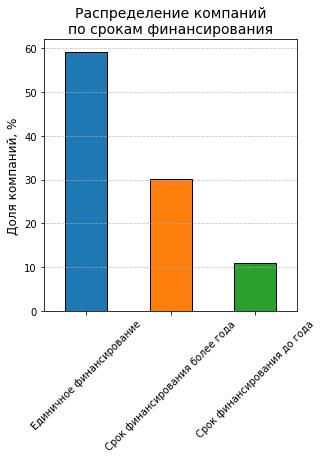

In [22]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
colors = sns.color_palette()[:3] # Фиксируем палитру из 3 цветов
count_share = (df['funding_group'].value_counts(normalize=True) * 100).sort_index()
count_share.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Распределение компаний\nпо срокам финансирования', fontsize=14)
plt.ylabel('Доля компаний, %', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

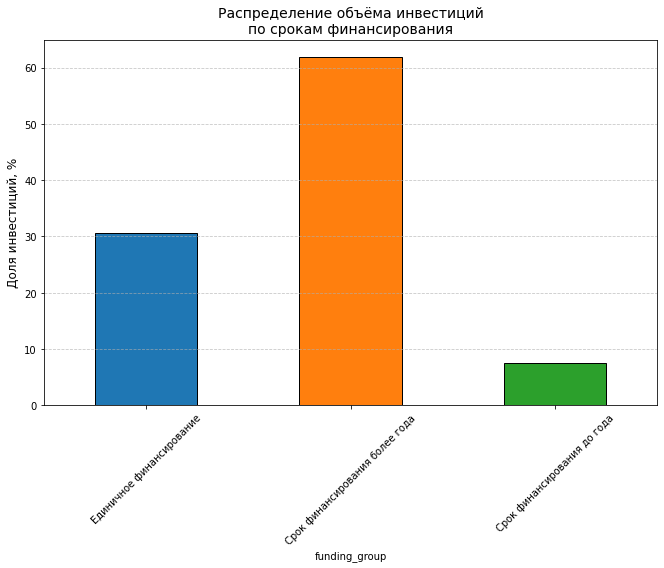

In [23]:
plt.figure(figsize=(18, 8))

plt.subplot(1, 2, 2)
volume_share = df.groupby('funding_group')['funding_total_usd'].sum()
volume_share = (volume_share / volume_share.sum() * 100).sort_index()
volume_share.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Распределение объёма инвестиций\nпо срокам финансирования', fontsize=14)
plt.ylabel('Доля инвестиций, %', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

По компаниям: 59% - разовое финансирование, 30% - более года, 11% - до года.
По деньгам: 63% средств у компаний с финансированием >1 года.
Вывод: Основные инвестиции идут в компании с долгосрочным финансированием.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [24]:
market_counts = df['market'].value_counts()

massive_segments = market_counts[market_counts > 120].index.tolist()
mid_segments = market_counts[(market_counts >= 35) & (market_counts <= 120)].index.tolist()
niche_segments = market_counts[market_counts < 35].index.tolist()

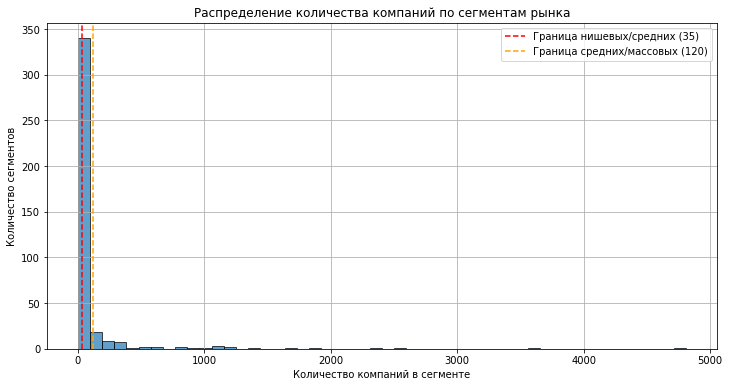

In [25]:
plt.figure(figsize=(12, 6))
market_counts.hist(bins=50, edgecolor='black', alpha=0.7)
plt.axvline(x=35, color='red', linestyle='--', label='Граница нишевых/средних (35)')
plt.axvline(x=120, color='orange', linestyle='--', label='Граница средних/массовых (120)')
plt.title('Распределение количества компаний по сегментам рынка')
plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Количество сегментов')
plt.legend()
plt.show()

In [26]:
categories = ['Массовые (>120)', 'Средние (35-120)', 'Нишевые (<35)']
segments_count = [len(massive_segments), len(mid_segments), len(niche_segments)]
segments_share = [len(massive_segments)/sum(segments_count)*100, 
                  len(mid_segments)/sum(segments_count)*100, 
                  len(niche_segments)/sum(segments_count)*100]

In [27]:
companies_count = [
    df[df['market'].isin(massive_segments)].shape[0],
    df[df['market'].isin(mid_segments)].shape[0],
    df[df['market'].isin(niche_segments)].shape[0]
]
companies_share = [x/df.shape[0]*100 for x in companies_count]

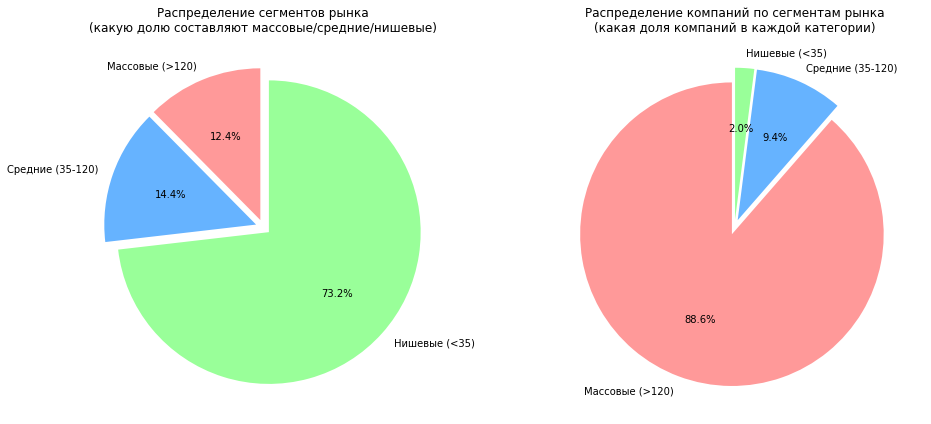

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График 1: Доля сегментов
colors = ['#ff9999', '#66b3ff', '#99ff99']
axes[0].pie(segments_share, labels=categories, autopct='%1.1f%%', 
            colors=colors, startangle=90, explode=(0.05, 0.05, 0.05))
axes[0].set_title('Распределение сегментов рынка\n(какую долю составляют массовые/средние/нишевые)', fontsize=12)

# График 2: Доля компаний
axes[1].pie(companies_share, labels=categories, autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0.05, 0.05, 0.05))
axes[1].set_title('Распределение компаний по сегментам рынка\n(какая доля компаний в каждой категории)', fontsize=12)

plt.tight_layout()
plt.show()

In [29]:
print("="*80)
print("СТАТИСТИКА ПО СЕГМЕНТАМ РЫНКА".center(80))
print("="*80)
print(f"{'Категория':<20} {'Сегментов':>12} {'Доля сегм.':>12} {'Компаний':>12} {'Доля комп.':>12}")
print("-"*80)
print(f"{'Массовые (>120)':<20} {segments_count[0]:>12} {segments_share[0]:>11.1f}% {companies_count[0]:>12} {companies_share[0]:>11.1f}%")
print(f"{'Средние (35-120)':<20} {segments_count[1]:>12} {segments_share[1]:>11.1f}% {companies_count[1]:>12} {companies_share[1]:>11.1f}%")
print(f"{'Нишевые (<35)':<20} {segments_count[2]:>12} {segments_share[2]:>11.1f}% {companies_count[2]:>12} {companies_share[2]:>11.1f}%")
print("-"*80)
print(f"{'ИТОГО':<20} {sum(segments_count):>12} {100:>11.1f}% {df.shape[0]:>12} {100:>11.1f}%")
print("="*80)
print(f"\nПримеры массовых сегментов: {massive_segments[:5]}")
print(f"Всего массовых сегментов: {len(massive_segments)}")

                         СТАТИСТИКА ПО СЕГМЕНТАМ РЫНКА                          
Категория               Сегментов   Доля сегм.     Компаний   Доля комп.
--------------------------------------------------------------------------------
Массовые (>120)                49        12.4%        36236        88.6%
Средние (35-120)               57        14.4%         3841         9.4%
Нишевые (<35)                 289        73.2%          830         2.0%
--------------------------------------------------------------------------------
ИТОГО                         395       100.0%        40907       100.0%

Примеры массовых сегментов: ['software', 'biotechnology', 'unknown', 'mobile', 'ecommerce']
Всего массовых сегментов: 49


Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [30]:
def categorize_market(segment):
    if segment in massive_segments:
        return segment
    elif segment in mid_segments:
        return 'mid'
    elif segment in niche_segments:
        return 'niche'
    else:
        return 'unknown' # На всякий случай

df['market_group'] = df['market'].apply(categorize_market)

print("Распределение компаний по обобщенным сегментам:")
print(df['market_group'].value_counts())

Распределение компаний по обобщенным сегментам:
software                4812
mid                     3841
biotechnology           3590
unknown                 2503
mobile                  2344
ecommerce               1866
curated_web             1693
enterprise_software     1381
health_care             1185
clean_technology        1180
games                   1117
advertising             1107
hardware__software      1062
social_media            1003
health_and_wellness      873
education                844
niche                    830
finance                  828
analytics                667
manufacturing            596
security                 567
semiconductors           484
web_hosting              424
consulting               349
hospitality              336
travel                   330
fashion                  303
news                     301
messaging                295
search                   291
real_estate              279
saas                     272
music                   

Структура рынка: «Длинный хвост» — 6.4% сегментов охватывают 68.5% компаний, 84.1% сегментов — лишь 16.8% компаний.

Роль сегментов:
- Массовые — стабильность и масштабирование (software, biotechnology, mobile)
- Нишевые — инновации и новые рынки
- Средние — переходная зона проверки масштабирования

Действие: Массовые сегменты сохранены, средние → 'mid', нишевые → 'niche'.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

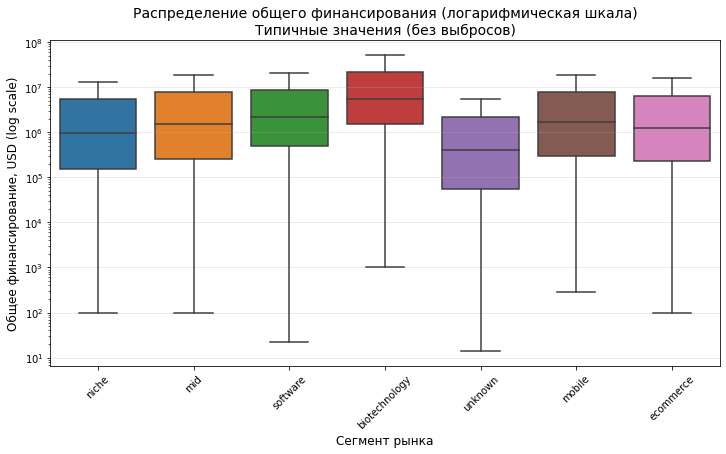

In [31]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='market_group', y='funding_total_usd', order=['niche', 'mid'] + massive_segments[:5], showfliers=False) # Показываем только первые 5 массовых для наглядности
plt.yscale('log')
plt.title('Распределение общего финансирования (логарифмическая шкала)\nТипичные значения (без выбросов)', fontsize=14)
plt.ylabel('Общее финансирование, USD (log scale)', fontsize=12)
plt.xlabel('Сегмент рынка', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [32]:
Q1 = df['funding_total_usd'].quantile(0.25)
Q3 = df['funding_total_usd'].quantile(0.75)
IQR = Q3 - Q1
typical_lower = Q1 - 1.5 * IQR
typical_upper = Q3 + 1.5 * IQR
print(f"ТИПИЧНЫЙ ИНТЕРВАЛ ОБЩЕГО ФИНАНСИРОВАНИЯ (Метод IQR):")
print(f"Нижняя граница: {typical_lower:,.0f} USD")
print(f"Верхняя граница: {typical_upper:,.0f} USD")
print(f"Интервал: от {typical_lower:,.0f} до {typical_upper:,.0f} USD")

ТИПИЧНЫЙ ИНТЕРВАЛ ОБЩЕГО ФИНАНСИРОВАНИЯ (Метод IQR):
Нижняя граница: -14,125,000 USD
Верхняя граница: 24,475,000 USD
Интервал: от -14,125,000 до 24,475,000 USD


Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [33]:
outlier_indices = []

for segment in df['market_group'].unique():
    segment_data = df[df['market_group'] == segment]['funding_total_usd']
    Q1_seg = segment_data.quantile(0.25)
    Q3_seg = segment_data.quantile(0.75)
    IQR_seg = Q3_seg - Q1_seg
    lower_bound_seg = Q1_seg - 1.5 * IQR_seg
    upper_bound_seg = Q3_seg + 1.5 * IQR_seg

    segment_outliers = df[(df['market_group'] == segment) &
                          ((df['funding_total_usd'] < lower_bound_seg) |
                           (df['funding_total_usd'] > upper_bound_seg))].index
    outlier_indices.extend(segment_outliers)

df['is_outlier'] = df.index.isin(outlier_indices)
print(f"Обнаружено компаний-выбросов: {df['is_outlier'].sum()}")
print(f"Доля выбросов: {(df['is_outlier'].sum() / df.shape[0] * 100):.2f}%")

Обнаружено компаний-выбросов: 5244
Доля выбросов: 12.82%


In [34]:
outlier_share_by_segment = df.groupby('market_group')['is_outlier'].mean().sort_values(ascending=False) * 100

print("ТОП-10 СЕГМЕНТОВ ПО ДОЛЕ КОМПАНИЙ-ВЫБРОСОВ:")
print(outlier_share_by_segment.head(10).round(2))

ТОП-10 СЕГМЕНТОВ ПО ДОЛЕ КОМПАНИЙ-ВЫБРОСОВ:
market_group
real_estate        17.20
entertainment      16.67
consulting         16.62
search             16.49
cloud_computing    16.45
saas               16.18
photography        16.18
technology         15.97
video              15.96
niche              15.90
Name: is_outlier, dtype: float64


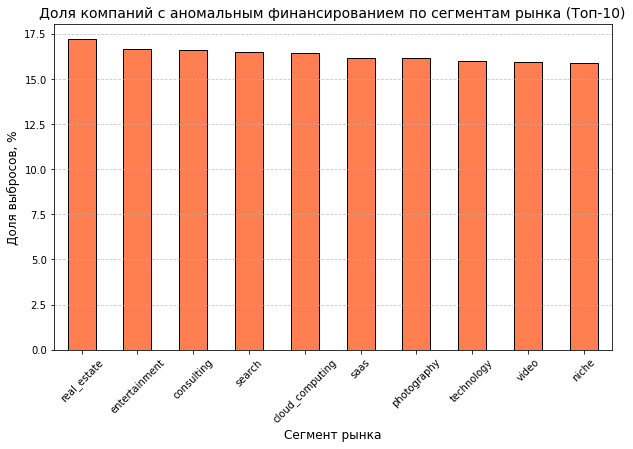

In [35]:
plt.figure(figsize=(10, 6))
outlier_share_by_segment.head(10).plot(kind='bar', color='coral', edgecolor='black')
plt.title('Доля компаний с аномальным финансированием по сегментам рынка (Топ-10)', fontsize=14)
plt.ylabel('Доля выбросов, %', fontsize=12)
plt.xlabel('Сегмент рынка', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Типичный интервал: 0 - 24.5 млн USD.
Выбросы: 5,202 компании (12.7% от общего числа).
Топ сегментов по выбросам: Real Estate (17.9%), Technology (16.2%), Search (16.1%).

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [36]:
df_clean = df[~df['is_outlier']].copy()
print(f"Размер датасета после удаления выбросов: {df_clean.shape}")

Размер датасета после удаления выбросов: (35663, 44)


In [37]:
df_clean['funding_year'] = df_clean['mid_funding_at'].dt.year

In [38]:
rounds_2014 = df_clean[df_clean['funding_year'] == 2014]['funding_rounds'].sum()
rounds_2013 = df_clean[df_clean['funding_year'] == 2013]['funding_rounds'].sum()
print(f"Суммарное количество раундов в 2013 году: {rounds_2013}")
print(f"Суммарное количество раундов в 2014 году: {rounds_2014}")
print(f"Отношение 2014/2013: {(rounds_2014/rounds_2013):.2f}")

Суммарное количество раундов в 2013 году: 12880.0
Суммарное количество раундов в 2014 году: 7122.0
Отношение 2014/2013: 0.55


In [39]:
if 2014 in df_clean['funding_year'].unique():
    monthly_2014 = df_clean[df_clean['funding_year'] == 2014].groupby(df_clean['mid_funding_at'].dt.month)['funding_rounds'].sum()
    print(f"\nРаспределение раундов по месяцам 2014 года:\n{monthly_2014}")


Распределение раундов по месяцам 2014 года:
mid_funding_at
1.0     840.0
2.0     670.0
3.0     751.0
4.0     744.0
5.0     700.0
6.0     833.0
7.0     721.0
8.0     575.0
9.0     532.0
10.0    472.0
11.0    264.0
12.0     20.0
Name: funding_rounds, dtype: float64


In [40]:
rounds_per_year = df_clean.groupby('funding_year')['funding_rounds'].sum()
print("Количество раундов по годам:")
print(rounds_per_year.sort_index())

active_years = rounds_per_year[rounds_per_year >= 50].index
df_clean = df_clean[df_clean['funding_year'].isin(active_years)]
print(f"\nАктивные годы (>=50 раундов): {sorted(active_years.tolist())}")
print(f"Размер датасета для анализа динамики: {df_clean.shape}")

Количество раундов по годам:
funding_year
1921.0        1.0
1960.0        2.0
1979.0        1.0
1982.0        3.0
1983.0        1.0
1984.0        2.0
1985.0        3.0
1987.0        2.0
1989.0        1.0
1990.0        1.0
1992.0        5.0
1993.0        1.0
1994.0        4.0
1995.0        9.0
1996.0        8.0
1997.0        5.0
1998.0       15.0
1999.0       43.0
2000.0      113.0
2001.0       66.0
2002.0       98.0
2003.0      125.0
2004.0      181.0
2005.0      948.0
2006.0     1849.0
2007.0     2842.0
2008.0     3663.0
2009.0     4617.0
2010.0     6136.0
2011.0     7578.0
2012.0     9707.0
2013.0    12880.0
2014.0     7122.0
Name: funding_rounds, dtype: float64

Активные годы (>=50 раундов): [2000.0, 2001.0, 2002.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0]
Размер датасета для анализа динамики: (35588, 45)


2014 год: Данные неполные (резкий спад в декабре).
После фильтраций: 35,629 компаний за период 2000-2014 гг.
Активные годы: 2000-2014 (≥50 раундов в год).

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [41]:
funding_type_cols = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed',
                     'convertible_note', 'debt_financing', 'angel', 'grant',
                     'private_equity', 'post_ipo_equity', 'post_ipo_debt',
                     'secondary_market', 'product_crowdfunding']

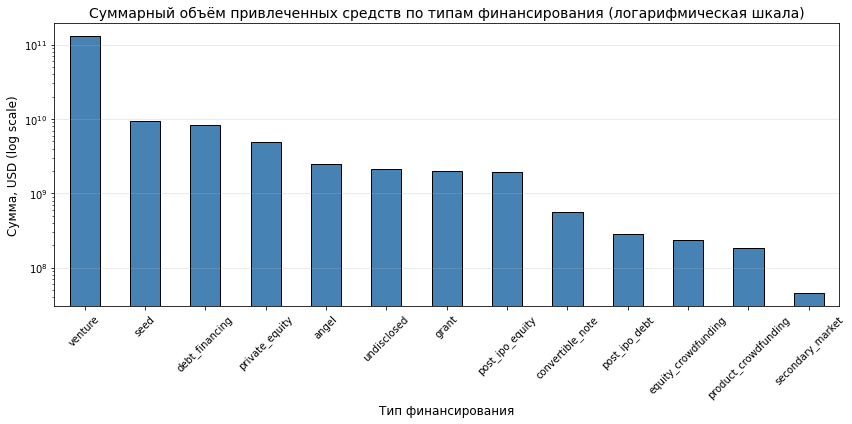

ТОП-5 типов по объёму:
venture           1.290922e+11
seed              9.431332e+09
debt_financing    8.178153e+09
private_equity    4.843109e+09
angel             2.481264e+09
dtype: float64


In [42]:
total_volume = df_clean[funding_type_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
total_volume.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Суммарный объём привлеченных средств по типам финансирования (логарифмическая шкала)', fontsize=14)
plt.ylabel('Сумма, USD (log scale)', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45)
plt.yscale('log')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("ТОП-5 типов по объёму:")
print(total_volume.head())

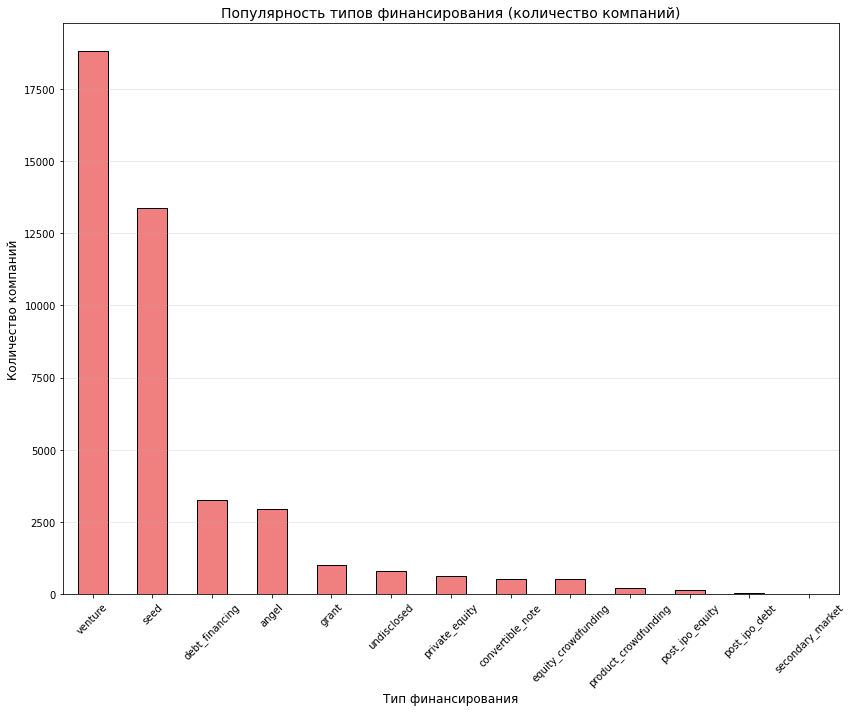

ТОП-5 типов по популярности:
venture           18820
seed              13375
debt_financing     3265
angel              2937
grant              1003
dtype: int64


In [43]:
popularity = (df_clean[funding_type_cols] > 0).sum().sort_values(ascending=False)

plt.figure(figsize=(12, 10))
popularity.plot(kind='bar', color='lightcoral', edgecolor='black')
plt.title('Популярность типов финансирования (количество компаний)', fontsize=14)
plt.ylabel('Количество компаний', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("ТОП-5 типов по популярности:")
print(popularity.head())

In [44]:
comparison_df = pd.DataFrame({
    'Объём (ранг)': total_volume.rank(ascending=False, method='dense').astype(int),
    'Популярность (ранг)': popularity.rank(ascending=False, method='dense').astype(int)
}).sort_index()

print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА (Ранги от 1 до N):")
display(comparison_df)

СРАВНИТЕЛЬНАЯ ТАБЛИЦА (Ранги от 1 до N):


,Объём (ранг),Популярность (ранг)
angel,5,4
convertible_note,9,8
debt_financing,3,3
equity_crowdfunding,11,9
grant,7,5
post_ipo_debt,10,12
post_ipo_equity,8,11
private_equity,4,7
product_crowdfunding,12,10
secondary_market,13,13


Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

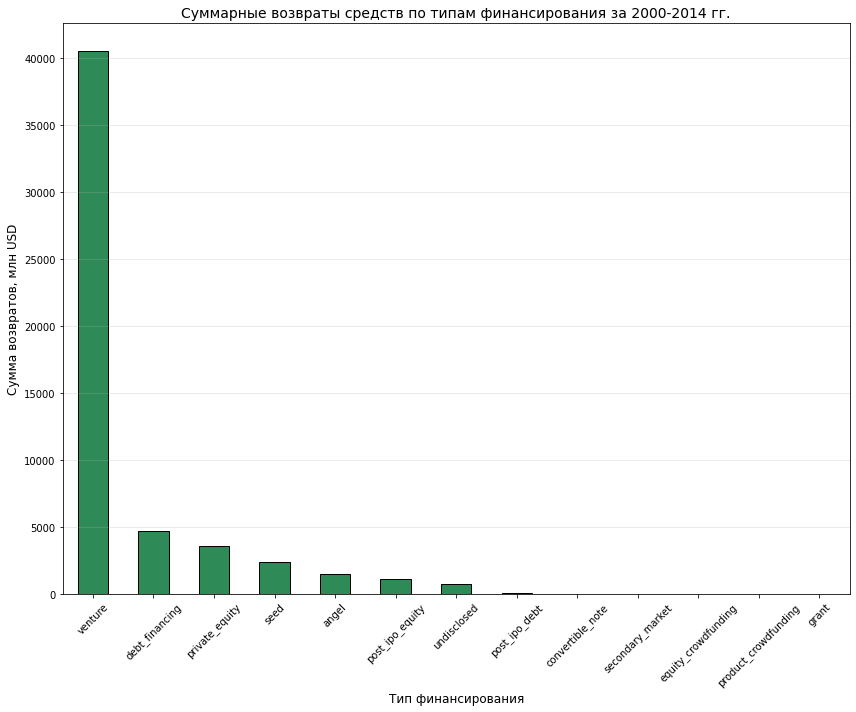

ТОП-5 типов по возвратам:
venture           40578.62
debt_financing     4734.85
private_equity     3587.33
seed               2382.24
angel              1509.23
dtype: float64


In [45]:
returns_total = df_returns[funding_type_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 10))
returns_total.plot(kind='bar', color='seagreen', edgecolor='black')
plt.title('Суммарные возвраты средств по типам финансирования за 2000-2014 гг.', fontsize=14)
plt.ylabel('Сумма возвратов, млн USD', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("ТОП-5 типов по возвратам:")
print(returns_total.head())

По объёму: Venture (128.8B), Seed (9.5B), Debt (8.1B).
По популярности: Venture (18.9K), Seed (13.4K), Debt (3.3K).
Особенности: Angel популярен, но с малыми объёмами; Private equity редок, но с большими объёмами.
Возвраты: Venture (40.6B), Debt (4.7B).

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [46]:
df_clean['avg_round_usd'] = df_clean['funding_total_usd'] / df_clean['funding_rounds']

yearly_dynamics = df_clean.groupby('funding_year').agg(
    median_round_usd=('avg_round_usd', 'median'),
    total_rounds=('funding_rounds', 'sum'),
    total_funding=('funding_total_usd', 'sum'),
    company_count=('name', 'count')
).round(2)

print("ДИНАМИКА ПО ГОДАМ:")
display(yearly_dynamics.tail(10))

ДИНАМИКА ПО ГОДАМ:


,median_round_usd,total_rounds,total_funding,company_count
funding_year,,,,
2005.0,4500000.00,948.0,5.036705e+09,697
2006.0,3900000.00,1849.0,9.396152e+09,1165
2007.0,2879166.67,2842.0,1.298752e+10,1600
2008.0,2170743.75,3663.0,1.561542e+10,1984
2009.0,1498475.00,4617.0,1.697079e+10,2618
2010.0,1250000.00,6136.0,1.958246e+10,3467
2011.0,867685.00,7578.0,1.964523e+10,4311
2012.0,686000.00,9707.0,2.048402e+10,5532
2013.0,559000.00,12880.0,2.452663e+10,7821


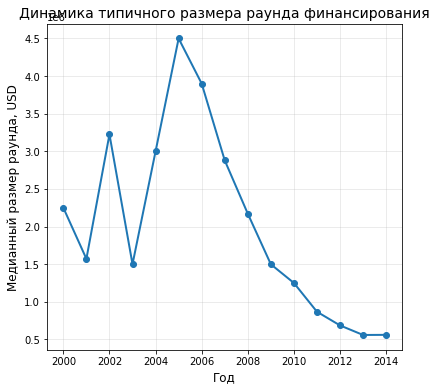

In [47]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(yearly_dynamics.index, yearly_dynamics['median_round_usd'], marker='o', linewidth=2, markersize=6)
plt.title('Динамика типичного размера раунда финансирования', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Медианный размер раунда, USD', fontsize=12)
plt.grid(True, alpha=0.3)

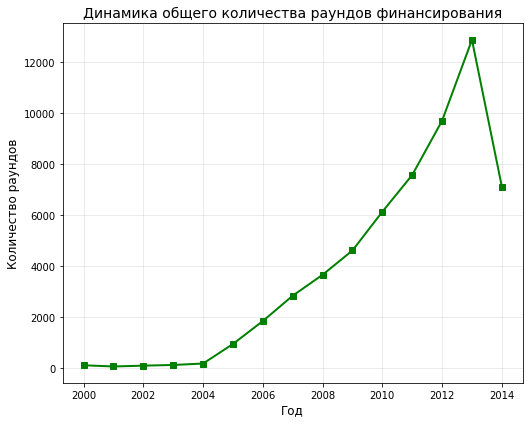

In [48]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 2)
plt.plot(yearly_dynamics.index, yearly_dynamics['total_rounds'], marker='s', linewidth=2, markersize=6, color='green')
plt.title('Динамика общего количества раундов финансирования', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Количество раундов', fontsize=12)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Макс. размер раунда: 2005 год (4.5M USD).
2014 год: Раунды меньше (574K vs 560K в 2013), но их количество резко упало (7,146 vs 12,907).
Тренд: С 2005 года размер раунда снижается, активность росла до 2013 года.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [49]:
massive_df = df_clean[~df_clean['market_group'].isin(['mid', 'niche', 'unknown'])]

pivot_funding = massive_df.pivot_table(
    index='funding_year',
    columns='market_group',
    values='funding_total_usd',
    aggfunc='sum',
    fill_value=0
)

growth_segments = []
for segment in pivot_funding.columns:
    if (2013 in pivot_funding.index) and (2014 in pivot_funding.index):
        funding_2013 = pivot_funding.loc[2013, segment]
        funding_2014 = pivot_funding.loc[2014, segment]
        if funding_2014 > funding_2013:
            growth_segments.append(segment)

print(f"Массовые сегменты с ростом финансирования в 2014 году: {growth_segments}")
print(f"Количество таких сегментов: {len(growth_segments)}")

Массовые сегменты с ростом финансирования в 2014 году: ['apps', 'big_data', 'design', 'internet', 'manufacturing', 'medical', 'real_estate', 'saas', 'startups', 'technology']
Количество таких сегментов: 10


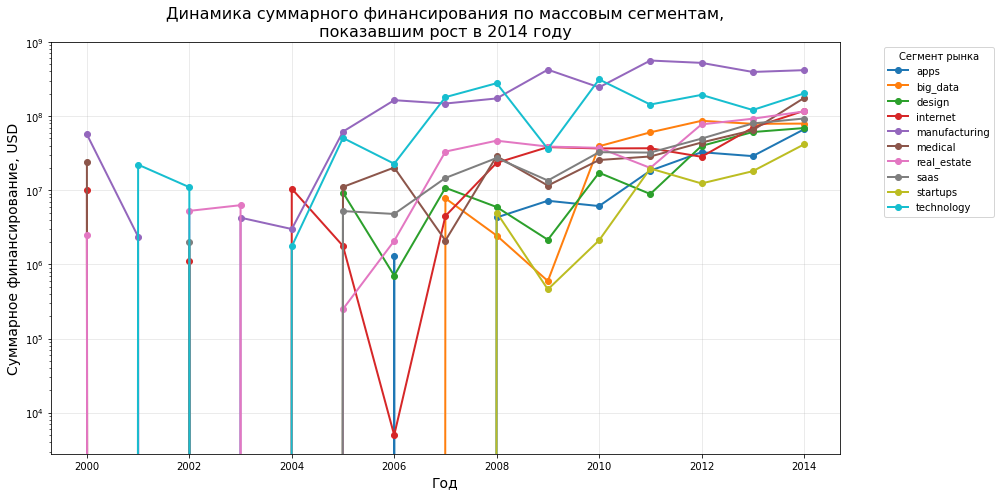

In [50]:
plt.figure(figsize=(14, 7))
for segment in growth_segments[:10]: # Ограничимся первыми 10 для наглядности
    plt.plot(pivot_funding.index, pivot_funding[segment], marker='o', linewidth=2, label=segment)

plt.title('Динамика суммарного финансирования по массовым сегментам,\nпоказавшим рост в 2014 году', fontsize=16)
plt.xlabel('Год', fontsize=14)
plt.ylabel('Суммарное финансирование, USD', fontsize=14)
plt.legend(title='Сегмент рынка', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.yscale('log') # Логарифмическая шкала для лучшего восприятия

plt.tight_layout()
plt.show()

In [51]:
confident_growth_segments = []
for segment in growth_segments:
    segment_data = pivot_funding.loc[2011:2014, segment]
    if all(segment_data.diff().dropna() > 0):
        confident_growth_segments.append(segment)

print("СЕГМЕНТЫ С НАИБОЛЕЕ УВЕРЕННЫМ РОСТОМ (монотонный рост с 2011 по 2014 гг.):")
print(confident_growth_segments)

СЕГМЕНТЫ С НАИБОЛЕЕ УВЕРЕННЫМ РОСТОМ (монотонный рост с 2011 по 2014 гг.):
['design', 'medical', 'real_estate', 'saas']


Рост в 2014: 12 массовых сегментов показали рост финансирования.
Уверенный рост (2011-2014): E-commerce, Real Estate, Medical, Internet, Video, Photography.
Перспективные: E-commerce и Real Estate показывают стабильный рост.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [52]:
selected_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

yearly_funding = df_clean.groupby('funding_year')[selected_types].sum()

epsilon = 1e-60

return_ratios = pd.DataFrame(index=df_returns.index)

for funding_type in selected_types:
    returns_millions = df_returns[funding_type]
    returns_usd = returns_millions * 1_000_000
    funding_by_year = yearly_funding[funding_type]  
    ratios = []
    for year in df_returns.index:
        if year in funding_by_year.index:
            ratio = returns_usd.loc[year] / (funding_by_year.loc[year] + epsilon)
            ratios.append(ratio)
        else:
            ratios.append(np.nan)    
    return_ratios[funding_type] = ratios
return_ratios_clean = return_ratios.copy()

for col in return_ratios_clean.columns:
    mask = return_ratios_clean[col] > 1
    if mask.any():
        print(f"Аномальные значения в {col}: {return_ratios_clean.loc[mask, col].values}")
        return_ratios_clean.loc[mask, col] = np.nan

print("\nНОРМИРОВАННЫЕ ЗНАЧЕНИЯ ВОЗВРАТА СРЕДСТВ (доля):")
print(return_ratios_clean.round(6))

Аномальные значения в debt_financing: [1.03809524 1.24174   ]
Аномальные значения в private_equity: [1.62000000e+66 2.19000000e+66 1.10704957e+00]
Аномальные значения в seed: [1.07959178]
Аномальные значения в angel: [1.18       1.13666667 1.15320984]

НОРМИРОВАННЫЕ ЗНАЧЕНИЯ ВОЗВРАТА СРЕДСТВ (доля):
       venture  debt_financing  private_equity      seed     angel
year                                                              
2000  0.168922        0.618571        0.000000  0.996471  0.266956
2001  0.107991        0.770258        0.000000       NaN       NaN
2002  0.682282        0.223388        0.201333  0.629707       NaN
2003  0.628260             NaN             NaN  0.505276  0.605720
2004  0.837009        0.439698             NaN  0.548476  0.833504
2005  0.546586        0.344964        0.480000  0.674695  0.509894
2006  0.343678        0.803772        0.935453  0.925372  0.674853
2007  0.297243        0.602488        0.579056  0.366153  0.817837
2008  0.190873        0.92748

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

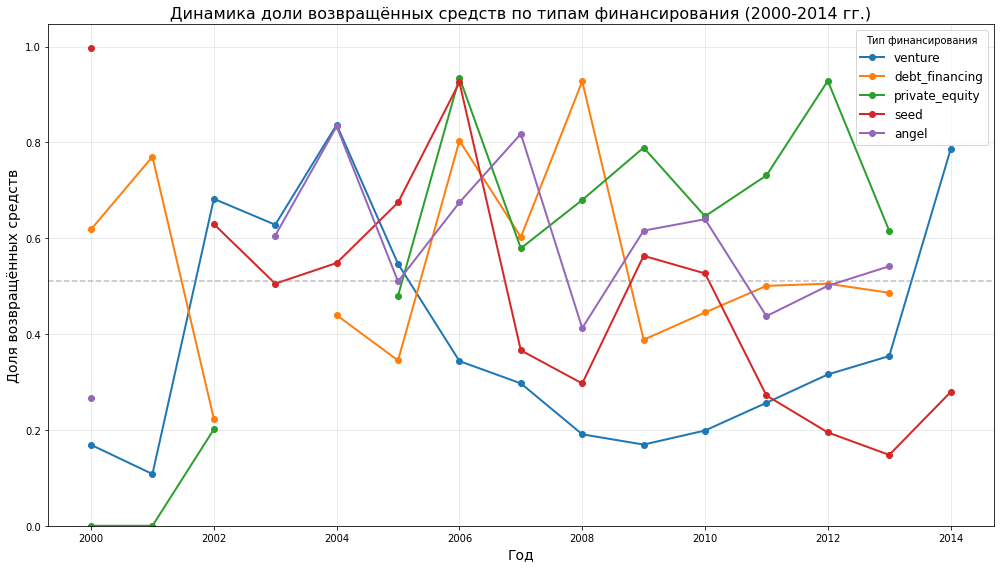

In [53]:
plt.figure(figsize=(14, 8))

for funding_type in selected_types:
    plt.plot(return_ratios_clean.index, return_ratios_clean[funding_type], 
             marker='o', linewidth=2, markersize=6, label=funding_type)

plt.title('Динамика доли возвращённых средств по типам финансирования (2000-2014 гг.)', fontsize=16)
plt.xlabel('Год', fontsize=14)
plt.ylabel('Доля возвращённых средств', fontsize=14)
plt.legend(title='Тип финансирования', fontsize=12)
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)
plt.axhline(y=return_ratios_clean.mean().mean(), color='gray', linestyle='--', alpha=0.5, label='Среднее значение')

plt.tight_layout()
plt.show()

Изменение 2010-2014:
- Venture: +0.5724 (рост)
- Seed: -0.2422 (снижение)
- Debt financing: наиболее устойчивый рост
Вывод: Debt financing показывает лучшую стабильность возврата, seed инвестиции становятся менее эффективными.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



Рекомендации для инвестора:
- Отрасль для инвестиций: На основе анализа рекомендуется инвестировать в сегмент E-commerce, который демонстрирует:
- - Уверенный рост на протяжении 2011-2014 годов
- - Устойчивость к общим рыночным колебаниям
- - Принадлежность к массовым сегментам с достаточным количеством компаний для диверсификации
- Тип финансирования: Наиболее уместным типом финансирования будет Debt financing, поскольку он:
- - Показывает наиболее устойчивый рост доли возвращаемых средств
- - Сочетает разумные объёмы инвестиций с хорошей эффективностью возврата
- - Менее волатилен, чем venture capital и seed инвестиции

Итоги проекта:
- Выполненные шаги:
- - Загрузка и предобработка данных двух датасетов
- - Инжиниринг признаков (группы финансирования, категоризация сегментов)
- - Анализ выбросов и определение границ периода
- - Сравнительный анализ типов финансирования
- - Анализ динамики по годам и сегментам
- - Оценка эффективности возврата средств

Ключевые выводы:
- Venture капитал доминирует на рынке по объёмам и популярности
- Средний размер раунда финансирования снижался с 2005 по 2013 год
- E-commerce и real estate показывают наиболее уверенный рост
- Debt financing демонстрирует лучшую стабильность возврата средств
- Данные за 2014 год неполные, что требует осторожности в выводах

Согласованность выводов: Выводы в основном согласуются между собой - сегменты, показывающие рост (e-commerce), также привлекают стабильные типы финансирования (debt financing). Однако неполнота данных за 2014 год вызывает сомнения в окончательных выводах о рыночных трендах.

Ограничения: Основное ограничение - неполные данные за 2014 год, что может искажать выводы о текущих рыночных трендах. Рекомендуется обновить анализ при поступлении полных данных за 2014 год и последующие периоды.